# VectorIA — EDA, ETL y entrenamiento LSTM provincial (bonus)

**Dataset:** `data/raw/vectoria_dengue_semanal.csv` (datos **sintéticos** de 2014–2025). 

**Objetivo:** pronosticar los casos de dengue de las próximas 4 semanas por provincia. Se usa un **solo LSTM** entrenado con las siete provincias. No modifica el LSTM nacional.

**Orden:** 1) validación → 2) limpieza climática → 3) EDA → 4) ventanas y split temporal → 5) entrenamiento y métricas → 6) inferencia de 2026.

> Las métricas de 2025 son retrospectivas (con ventanas históricas observadas); la predicción real de 2026 es recursiva y su incertidumbre crece con el horizonte.

In [19]:
from pathlib import Path
import sys

# Localiza la raíz del proyecto; funciona ejecutando Jupyter desde VectorIA o desde notebooks/EDA/LSTM.
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "raw" / "vectoria_dengue_semanal.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError(
        "No se encontró data/raw/vectoria_dengue_semanal.csv. "
        "Abra Jupyter desde VectorIA o desde una subcarpeta del proyecto."
    )

# Priorizar esta carpeta para evitar importar otro proyecto con el mismo nombre.
if str(raiz) in sys.path:
    sys.path.remove(str(raiz))
sys.path.insert(0, str(raiz))
print("Raíz del proyecto:", raiz)


Raíz del proyecto: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA


## 1. Carga y validación del archivo original

In [20]:
import importlib
import inspect
import numpy as np
import pandas as pd
import src.train.lstm_provincial as modulo_provincial

# Recarga las funciones desde el archivo guardado, incluso si ya se ejecutó el notebook.
modulo_provincial = importlib.reload(modulo_provincial)
print("Módulo usado:", modulo_provincial.__file__)

# Evita ejecutar la versión antigua del train, que provocaba el error de encabezados.
if "df.columns = COLUMNS" not in inspect.getsource(modulo_provincial.leer_y_validar):
    raise RuntimeError(
        "El notebook está leyendo una versión antigua de src/train/lstm_provincial.py. "
        "Guarde el archivo corregido (el que incluye 'df.columns = COLUMNS'), "
        "reinicie el kernel y vuelva a ejecutar desde la primera celda."
    )

DATA_PATH = modulo_provincial.DATA_PATH
COLUMNS = modulo_provincial.COLUMNS
PROVINCIAS = modulo_provincial.PROVINCIAS
CLIMA = modulo_provincial.CLIMA
leer_y_validar = modulo_provincial.leer_y_validar

# Visualización del CSV original sin depender de cómo estén escritos sus encabezados.
primera_linea = DATA_PATH.read_text(encoding="utf-8-sig").splitlines()[0]
encabezado = primera_linea.strip().lower().startswith("fecha_inicio_semana,")
original = pd.read_csv(DATA_PATH, header=0 if encabezado else None, encoding="utf-8-sig")
if len(original.columns) != len(COLUMNS):
    raise ValueError(f"El CSV tiene {len(original.columns)} columnas y se esperaban {len(COLUMNS)}.")
original.columns = COLUMNS

print("Dimensiones:", original.shape)
display(original.head())
print("Nulos originales:")
display(original.isna().sum().to_frame("nulos"))
print("Duplicados por provincia + fecha:", original.duplicated(["provincia", "fecha_inicio_semana"]).sum())


Módulo usado: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\src\train\lstm_provincial.py
Dimensiones: (4382, 12)


,fecha_inicio_semana,anio,semana_epi,provincia,region,poblacion,casos_dengue,incidencia_100k,lluvia_mm,temp_max,temp_min,humedad
0,2014-01-05,2014,2,Alajuela,Valle Central,1100000,27,2.45,0.0,27.1,18.9,58.1
1,2014-01-12,2014,3,Alajuela,Valle Central,1100000,10,0.91,0.0,27.3,17.6,64.0
2,2014-01-19,2014,4,Alajuela,Valle Central,1100000,32,2.91,0.0,28.7,18.8,59.4
3,2014-01-26,2014,5,Alajuela,Valle Central,1100000,22,2.00,0.0,28.9,19.2,65.4
4,2014-02-02,2014,6,Alajuela,Valle Central,1100000,15,1.36,0.0,29.3,19.0,65.4


Nulos originales:


,nulos
fecha_inicio_semana,0
anio,0
semana_epi,0
provincia,0
region,0
poblacion,0
casos_dengue,0
incidencia_100k,0
lluvia_mm,35
temp_max,34


Duplicados por provincia + fecha: 0


## 2. ETL: tipos, orden temporal y nulos climáticos

In [21]:
datos, reporte = leer_y_validar(DATA_PATH)
print("Reporte ETL:")
display(pd.DataFrame([reporte["nulos_clima_originales"]], index=["Nulos originales de clima"]))
print("Nulos luego de imputar:", int(datos[CLIMA].isna().sum().sum()))
print("Filas:", reporte["filas"], "Provincias:", len(reporte["provincias"]))
print("Fechas:", reporte["inicio"], "a", reporte["fin"])
display(datos[["fecha_inicio_semana", "provincia", "casos_dengue", *CLIMA]].head())

Reporte ETL:


,lluvia_mm,temp_max,temp_min,humedad
Nulos originales de clima,35,34,0,29


Nulos luego de imputar: 0
Filas: 4382 Provincias: 7
Fechas: 2014-01-05 a 2025-12-28


,fecha_inicio_semana,provincia,casos_dengue,lluvia_mm,temp_max,temp_min,humedad
0,2014-01-05,Alajuela,27,0.0,27.1,18.9,58.1
1,2014-01-12,Alajuela,10,0.0,27.3,17.6,64.0
2,2014-01-19,Alajuela,32,0.0,28.7,18.8,59.4
3,2014-01-26,Alajuela,22,0.0,28.9,19.2,65.4
4,2014-02-02,Alajuela,15,0.0,29.3,19.0,65.4


**ETL aplicado:** `fecha_inicio_semana` pasa a fecha, los valores numéricos se convierten a sus tipos, se ordena por provincia y fecha, se valida la periodicidad de domingos, no se eliminan filas y los nulos **solo climáticos** se interpolan dentro de la provincia. `casos_dengue` no se altera. Se crea `log_casos = log1p(casos_dengue)`, variables de estacionalidad y codificación de las provincias. El CSV original permanece intacto.

Para la fase anual se utiliza la fecha real, no se asume que `semana_epi` siga la convención ISO.

## 3. EDA: distribución y evolución de casos por provincia

,registros,media,mediana,maximo,total
provincia,,,,,
Alajuela,626,42.00,29.0,341,26290
Cartago,626,2.04,1.0,13,1277
Guanacaste,626,28.58,15.0,229,17891
Heredia,626,8.21,6.0,62,5139
Limón,626,28.41,20.0,294,17784
Puntarenas,626,35.84,26.5,276,22436
San José,626,33.46,22.0,241,20943


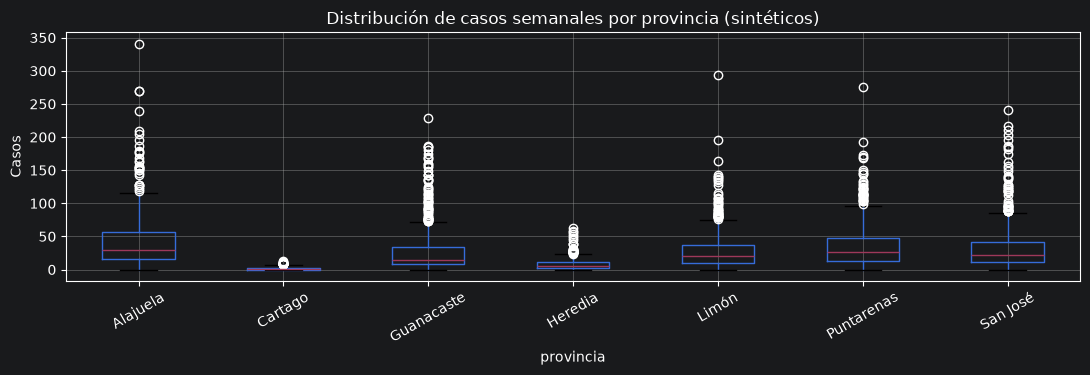

In [22]:
import matplotlib.pyplot as plt
resumen = datos.groupby("provincia").agg(registros=("casos_dengue", "size"),
                                         media=("casos_dengue", "mean"),
                                         mediana=("casos_dengue", "median"),
                                         maximo=("casos_dengue", "max"),
                                         total=("casos_dengue", "sum"))
display(resumen.round(2))
fig, ax = plt.subplots(figsize=(11, 4))
datos.boxplot(column="casos_dengue", by="provincia", ax=ax, rot=30)
plt.suptitle("")
ax.set_title("Distribución de casos semanales por provincia (sintéticos)")
ax.set_ylabel("Casos"); plt.tight_layout(); plt.show()

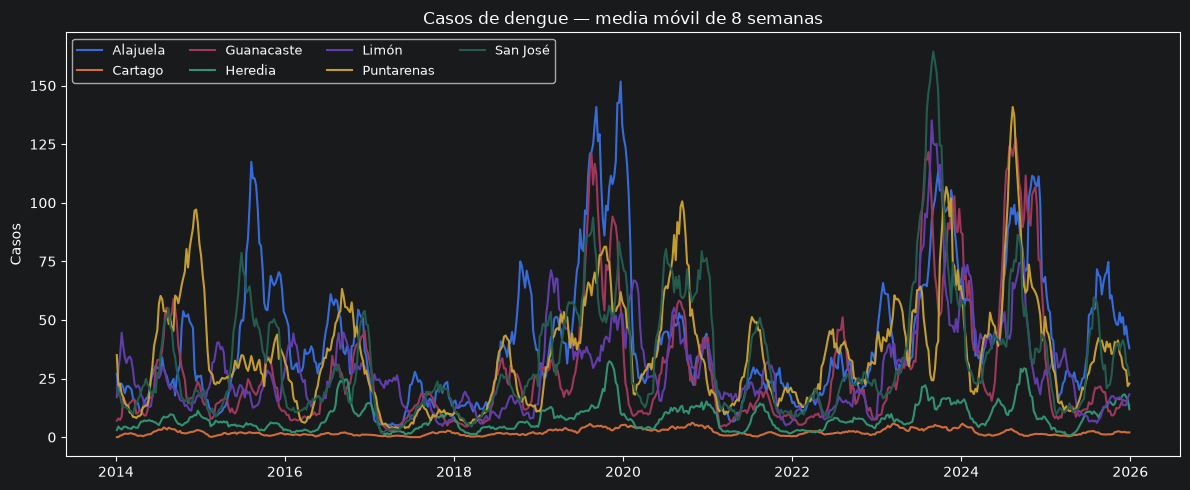

In [23]:
fig, ax = plt.subplots(figsize=(12, 5))
for provincia, grupo in datos.groupby("provincia"):
    ax.plot(grupo["fecha_inicio_semana"], grupo["casos_dengue"].rolling(8, min_periods=1).mean(), label=provincia)
ax.set(title="Casos de dengue — media móvil de 8 semanas", ylabel="Casos")
ax.legend(ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

## 4. EDA: variables climáticas y correlaciones

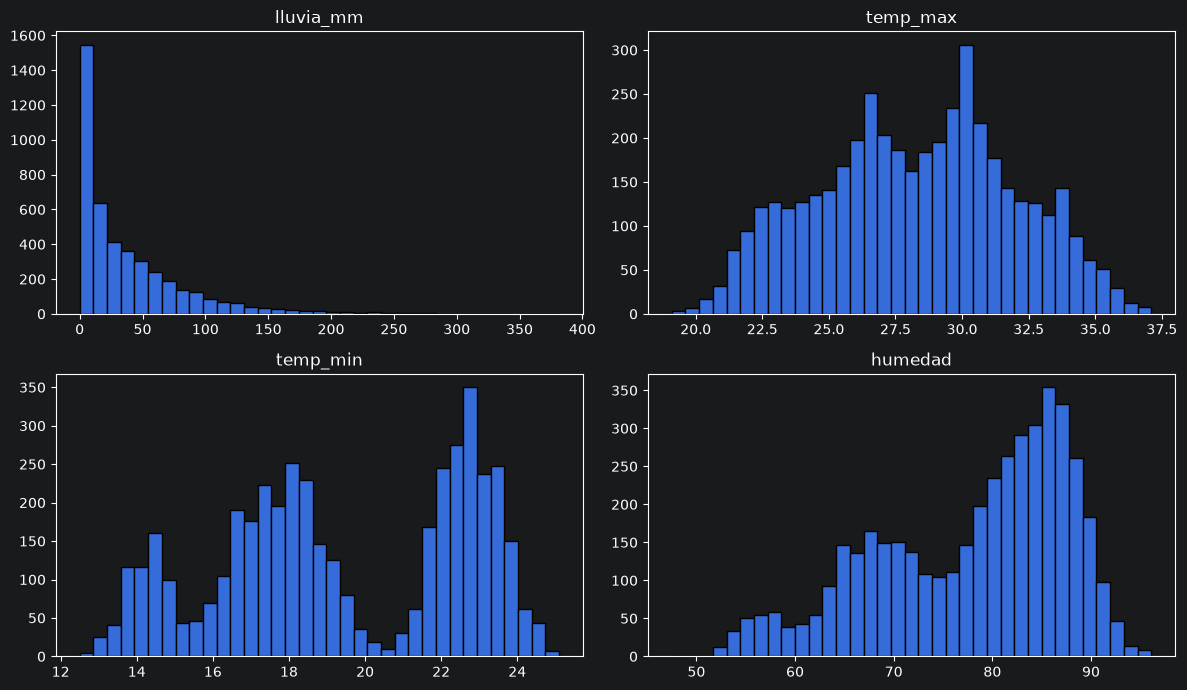

,casos_dengue,lluvia_mm,temp_max,temp_min,humedad
casos_dengue,1.000,0.084,0.234,0.267,0.026
lluvia_mm,0.084,1.000,-0.092,0.114,0.572
temp_max,0.234,-0.092,1.000,0.918,-0.418
temp_min,0.267,0.114,0.918,1.000,-0.191
humedad,0.026,0.572,-0.418,-0.191,1.000


In [24]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axs.flat, CLIMA):
    ax.hist(datos[col], bins=35, edgecolor="black")
    ax.set_title(col)
plt.tight_layout(); plt.show()

corr = datos[["casos_dengue", *CLIMA]].corr(numeric_only=True)
display(corr.round(3))

## 5. Partición temporal (no aleatoria) y diseño del modelo

In [25]:
VENTANA = modulo_provincial.VENTANA
HORIZONTE = modulo_provincial.HORIZONTE
FEATURES = modulo_provincial.FEATURES
print("Entrada:", VENTANA, "semanas ×", len(FEATURES), "variables")
print("Salida:", HORIZONTE, "semanas")
print("Entrenamiento: hasta 2023; validación: 2024; prueba: 2025")
print("Columnas de entrada:", FEATURES)
print("No se mezclan observaciones futuras en la escala de entrenamiento")


Entrada: 26 semanas × 14 variables
Salida: 4 semanas
Entrenamiento: hasta 2023; validación: 2024; prueba: 2025
Columnas de entrada: ['log_casos', 'lluvia_mm', 'temp_max', 'temp_min', 'humedad', 'semana_sin', 'semana_cos', 'prov_0', 'prov_1', 'prov_2', 'prov_3', 'prov_4', 'prov_5', 'prov_6']
No se mezclan observaciones futuras en la escala de entrenamiento


## 6. Entrenar LSTM y guardar artefactos

Se recomienda ejecutar **una sola vez**. Guarda modelo, escaladores y métricas en `models/LSTM_Provincial/`.

In [26]:
# Usa la misma versión recargada del módulo que pasó la validación del EDA.
metricas, historia = modulo_provincial.entrenar(epochs=40, batch_size=64)
display(pd.DataFrame(metricas).T)
print("Guardado en:", modulo_provincial.OUT_DIR)



[TensorFlow DLL Diagnostic] Analyzing: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\.venv\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\.venv\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: Error en una rutina de inicialización de biblioteca de vínculos dinámicos (DLL).


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

## 7. Curvas de entrenamiento

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historia["loss"], label="Train loss")
ax.plot(historia["val_loss"], label="Validation loss")
ax.set(title="Pérdida de entrenamiento", xlabel="Época", ylabel="MSE sobre log-casos estandarizados")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Prueba de predicción: las siete provincias / provincia específica

In [ ]:
from api.services.lstm_provincial_service import predecir_dengue_provincial
respuesta = predecir_dengue_provincial("2026-01-04")
print("Estado:", respuesta["estado"], "Fecha:", respuesta["primera_semana"])
display(pd.DataFrame([{"Provincia": r["provincia"], "Total cuatro semanas": r["total_4_semanas"]}
                      for r in respuesta["resultados"]]))
cartago = predecir_dengue_provincial("2026-06-14", provincia="Cartago")
display(pd.DataFrame(cartago["resultados"][0]["predicciones"]))

## 9. Interpretación y límites

- **MAE / RMSE menores son mejores**; comparar con `baseline_estacional_MAE/RMSE` de 2025 antes de juzgar desempeño.
- El pronóstico provincial usa **datos sintéticos**. No presentarlo como vigilancia epidemiológica real.
- El pronóstico para fechas avanzadas de 2026 recurre a predicciones previas (no dispone de clima observado de 2026). Por ello aumenta la incertidumbre.
- El mapa ya existente se conectará posteriormente al endpoint para mostrar la predicción de las siete provincias y destacar la seleccionada.